# 05 — Evaluation

**Question:** how robust are the phase 6 conclusions? In particular, is "GPS adds no forecasting skill beyond past seismicity" an artefact of how we scored or set up the models?

Phase 6 (`04_models`) scored expected counts and probabilities with single numbers over one setup. This notebook:

1. Scores **whole predictive distributions** for counts, not just the expected count.
2. Scores probability forecasts completely: **skill against climatology, ranking (ROC and precision-recall AUC), calibration**, and recalibrated versions of every forecaster.
3. States **the smallest difference each test could detect**, so "no gain" has a size.
4. Repeats the GPS ablation under **different setups**: training start, training window, forecast horizon, magnitude threshold.
5. Summarises everything for the README.

Forecasts come from `src/experiments.py`, which runs each forecaster through the same walk-forward evaluation as before and caches the results in `data/processed/forecasts/` (delete that folder to recompute). Every result is reported for **2020–2025** (312 weeks) and for the **steady period 2024–2025** (104 weeks), when the rate of seismicity changed least: over 2020–2025 some scores are flattered simply by telling quiet years from busy ones.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.evaluation import (add_horizon_targets, add_threshold_targets, count_scores, distribution_scores,
                            paired_difference, poisson_deviance, rolling_dispersion, weekly_poisson_deviance)
from src.experiments import MAIN, SENSITIVITY, run
from src.features import build_features

warnings.filterwarnings("ignore", category=RuntimeWarning)
events = pd.read_parquet("../data/processed/catalogue.parquet")
gps = pd.read_parquet("../data/processed/gps_daily.parquet")
# The table runs to late January 2026 so that 4-week targets exist for the last test weeks.
table = build_features(events, gps, "2005-01-03", "2026-01-25")
table = add_threshold_targets(add_horizon_targets(table, 4), events, 2.5, "25")

TEST_START, TEST_END, STEADY_START = "2020-01-06", "2025-12-22", "2024-01-01"
# The main forecasts start in 2017, so that each test week has past forecasts to calibrate on.
main = run(table, MAIN, "2017-01-02", TEST_END)
test = table.loc[TEST_START:TEST_END]
steady = test.index >= STEADY_START
periods = {"2020–2025": np.ones(len(test), bool), "2024–2025": steady}
print(f"{len(test)} test weeks; {steady.sum()} in 2024–2025. Count forecasters: {list(main['counts'].columns)}")
print(f"Probability forecasters: {list(main['probs'].columns)}")

312 test weeks; 104 in 2024–2025. Count forecasters: ['rolling_mean_4w', 'glm_seismic', 'glm_all', 'paper_rate', 'lgbm_seismic']
Probability forecasters: ['climatology_52w', 'bar', 'recalibrated', 'recalibrated_gps']


## 1. Full predictive distributions for counts

A count forecast so far was one number, the expected count μ. A useful forecast should also say **how uncertain** it is. A Poisson distribution with mean μ has variance μ, which is far too little for a swarm-prone volcano. The **negative binomial** (NB) adds a dispersion parameter α: variance = μ + α·μ². With α = 0 it is the Poisson distribution.

For each count model, α is fitted (by maximum likelihood) on the **104 weeks before each test week**: how much the observed counts scattered around that model's own earlier forecasts. Forecasts from 2017 on provide those earlier weeks, so no test week is used for its own α.

Scores for whole distributions (lower is better for both):

- **Log score:** −log of the probability the forecast gave to the count that happened.
- **Ranked probability score (RPS):** for every threshold k, the squared difference between the forecast P(count ≤ k) and what happened (0 or 1), summed over k: the Brier score summed over all thresholds.

Calibration checks:

- **Coverage:** how often the count fell inside the central 80% and 95% prediction intervals (should be 80% and 95%).
- **PIT histogram:** where each observed count fell within its forecast distribution (0 = far below, 1 = far above). If the distributions are right, every value is equally likely and the histogram is flat. A U shape means the forecasts are too narrow (counts keep landing in the tails).

In [2]:
y_all = table.loc["2017-01-02":TEST_END, "count"]
counts = main["counts"]
dispersion = {name: rolling_dispersion(y_all, counts[name], TEST_START) for name in counts.columns}
dist = {name: {"NB": distribution_scores(test["count"], counts[name].loc[TEST_START:], dispersion[name]),
               "Poisson": distribution_scores(test["count"], counts[name].loc[TEST_START:], 1e-4)}
        for name in counts.columns}

rows = {}
for name in counts.columns:
    for family in ["Poisson", "NB"]:
        d = dist[name][family]
        rows[(name, family)] = {
            **{f"log_score {p}": d["log_score"][m].mean() for p, m in periods.items()},
            **{f"rps {p}": d["rps"][m].mean() for p, m in periods.items()},
            "in_80 (2020–25)": d["in_80"].mean(), "in_95 (2020–25)": d["in_95"].mean(),
        }
pd.DataFrame(rows).T.round(2)

log_score 2020–2025  log_score 2024–2025  \
rolling_mean_4w Poisson                 9.14                16.32   
                NB                      3.44                 4.51   
glm_seismic     Poisson                 8.44                14.74   
                NB                      3.36                 4.38   
glm_all         Poisson                 8.57                15.10   
                NB                      3.37                 4.40   
paper_rate      Poisson                10.93                19.02   
                NB                      4.07                 4.76   
lgbm_seismic    Poisson                 9.16                16.15   
                NB                      3.40                 4.43   

                         rps 2020–2025  rps 2024–2025  in_80 (2020–25)  \
rolling_mean_4w Poisson          10.54          21.51             0.45   
                NB                8.41          16.85             0.86   
glm_seismic     Poisson           9.96          20.53             0.45   
                NB                8.04          16.05             0.88   
glm_all         Poisson          10.14          21.19             0.45   
                NB                8.07          16.21             0.89   
paper_rate      Poisson           9.99          20.64             0.44   
                NB                9.02          18.16             0.90   
lgbm_seismic    Poisson          10.47          22.09             0.44   
                NB                8.41          16.91             0.86   

                         in_95 (2020–25)  
rolling_mean_4w Poisson             0.60  
                NB                  0.95  
glm_seismic     Poisson             0.60  
                NB                  0.96  
glm_all         Poisson             0.63  
                NB                  0.96  
paper_rate      Poisson             0.54  
                NB                  0.95  
lgbm_seismic    Poisson             0.63  
                NB                  0.96

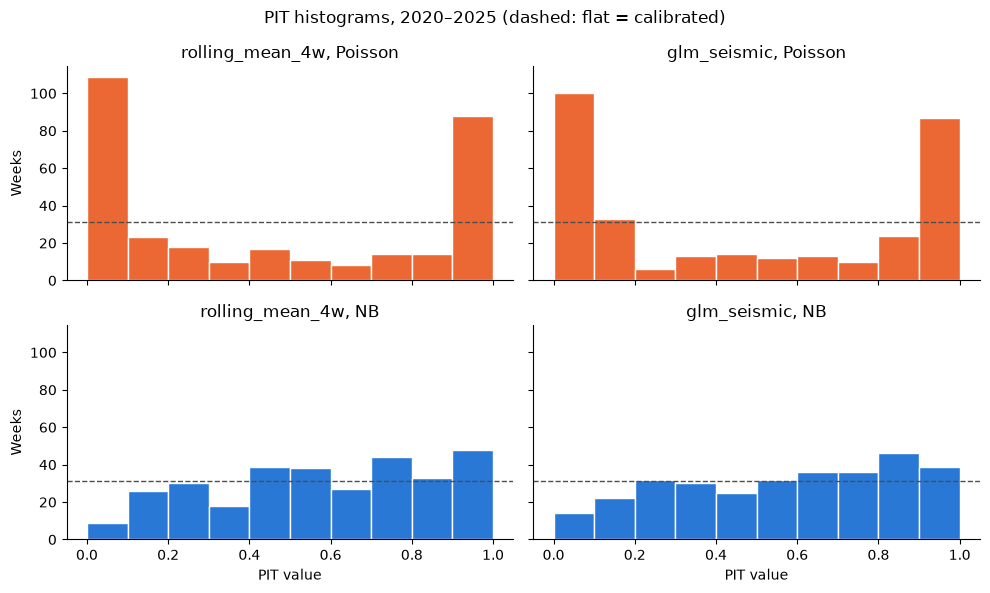

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for col, name in enumerate(["rolling_mean_4w", "glm_seismic"]):
    for row, family in enumerate(["Poisson", "NB"]):
        ax = axes[row, col]
        ax.hist(dist[name][family]["pit"], bins=10, range=(0, 1), color="#2a78d6" if family == "NB" else "#eb6834",
                edgecolor="white")
        ax.axhline(len(test) / 10, color="0.3", linewidth=1, linestyle="--")
        ax.set_title(f"{name}, {family}")
        ax.spines[["top", "right"]].set_visible(False)
for ax in axes[1]:
    ax.set_xlabel("PIT value")
for ax in axes[:, 0]:
    ax.set_ylabel("Weeks")
fig.suptitle("PIT histograms, 2020–2025 (dashed: flat = calibrated)")
plt.tight_layout()
plt.show()

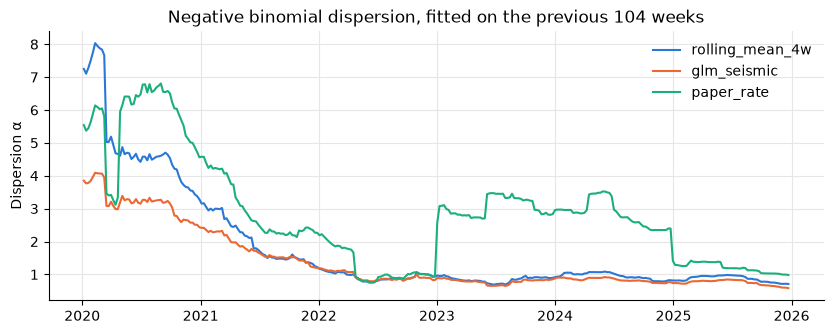

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for name, colour in [("rolling_mean_4w", "#2a78d6"), ("glm_seismic", "#eb6834"), ("paper_rate", "#1baf7a")]:
    ax.plot(dispersion[name].index, dispersion[name], linewidth=1.5, color=colour, label=name)
ax.set_ylabel("Dispersion α")
ax.set_title("Negative binomial dispersion, fitted on the previous 104 weeks")
ax.grid(True, color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
plt.show()

In [5]:
# Paired comparisons of the NB scores (negative = first model better).
pairs = [("glm_all", "glm_seismic", "GPS added (GLM)"),
         ("glm_seismic", "rolling_mean_4w", "GLM (seismic) against the bar"),
         ("lgbm_seismic", "glm_seismic", "LightGBM against GLM"),
         ("paper_rate", "rolling_mean_4w", "paper's model against the bar")]
pd.concat({f"{score}, {p}": pd.DataFrame({label: paired_difference(dist[a]["NB"][score][m], dist[b]["NB"][score][m])
                                          for a, b, label in pairs}).T
           for score in ["log_score", "rps"] for p, m in periods.items()}, axis=1).round(3)

log_score, 2020–2025                 \
                                   mean_difference ci_low ci_high   
GPS added (GLM)                              0.005 -0.025   0.038   
GLM (seismic) against the bar               -0.083 -0.144  -0.027   
LightGBM against GLM                         0.043  0.009   0.080   
paper's model against the bar                0.630  0.191   1.278   

                              log_score, 2024–2025                 \
                                   mean_difference ci_low ci_high   
GPS added (GLM)                              0.022 -0.007   0.052   
GLM (seismic) against the bar               -0.128 -0.229  -0.019   
LightGBM against GLM                         0.045 -0.014   0.102   
paper's model against the bar                0.247  0.107   0.494   

                               rps, 2020–2025                 rps, 2024–2025  \
                              mean_difference ci_low ci_high mean_difference   
GPS added (GLM)                         0.029 -0.221   0.253           0.160   
GLM (seismic) against the bar          -0.368 -0.946   0.108          -0.801   
LightGBM against GLM                    0.373  0.036   0.770           0.869   
paper's model against the bar           0.610 -0.415   1.725           1.317   

                                              
                              ci_low ci_high  
GPS added (GLM)               -0.584   0.846  
GLM (seismic) against the bar -2.328   0.444  
LightGBM against GLM          -0.000   1.986  
paper's model against the bar -1.558   4.642

**What section 1 shows:**

- **Poisson forecasts are far too confident.** Their 80% intervals contained the count in only 44–45% of weeks and their 95% intervals in 54–63%; the PIT histograms are strongly U-shaped (counts keep landing in the tails). With the negative binomial, coverage is about right (86–90% and 95–96%; slightly too wide at 80%), and the log score improves from about 8–11 to 3.4–4.1.
- **The spread is large:** α settles at about 0.8–1.0 for the seismicity-based models from 2022 on. For an expected 20 events a week that is a standard deviation of about 19 (Poisson: 4.5). It was larger in 2020–2021, when weeks were mostly quiet with rare bursts. The paper's model needs a much larger α (about 3 in 2023–2024): its means miss the swarms, so the distribution has to be wider to cover them.
- **The NB histograms tilt slightly upwards:** observed counts land a little more often in the upper half of the forecast distributions. The forecasts are slightly too low on average, as expected while the rate keeps growing.
- **With whole distributions, the GLM's gain over the bar becomes significant.** On the log score, the seismic GLM beats the 4-week rolling mean by 0.083 per week over 2020–2025 (interval −0.144 to −0.027) and by 0.128 in 2024–2025 (−0.229 to −0.019). The Poisson deviance in phase 6 couldn't confirm this, because a few swarm weeks dominated it; the log score with a realistic spread is less at the mercy of those weeks. (The RPS points the same way but its intervals include zero.)
- **GPS still adds nothing:** adding GPS to the GLM changes the log score by +0.005 (interval −0.025 to +0.038) over 2020–2025 and +0.022 (−0.007 to +0.052) in 2024–2025.
- LightGBM is significantly worse than the GLM on the log score over 2020–2025, and the paper's model significantly worse than the bar, as before.